In [1]:
import gc
import os
import statistics
import sys
import time
import tracemalloc
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sys.path.append("..")
from src.apriori import run_apriori
from src.fpgrowth import run_fpgrowth
from src.association_rules import generate_rules
from src.transactions import load_transactions

# True = tes pakai sampel 2024, False = data penuh 2015-2025
USE_SAMPLE = False

if USE_SAMPLE:
    TX_PATH = "../data/sample/tx_author_based_sample.pkl"
    SUFFIX = "_sample"
else:
    TX_PATH = "../data/processed/tx_author_based.pkl"
    SUFFIX = ""

FIGURES_DIR = "../figures"
STATS_OUT_DIR = "../data/results"
os.makedirs(FIGURES_DIR, exist_ok=True)
os.makedirs(STATS_OUT_DIR, exist_ok=True)

# parameter sama dengan task 4 dan task 5
MIN_SUPPORTS = [0.001, 0.005, 0.01, 0.02]
MIN_CONFIDENCE = 0.5
N_RUNS = 3

ALGORITHMS = {"Apriori": run_apriori, "FP-Growth": run_fpgrowth}

# transactional db yang sama untuk kedua algoritma (author-based)
transactions = load_transactions(TX_PATH)
N = len(transactions)
print(f"Transaksi: {TX_PATH}")
print(f"Jumlah transaksi: {N:,}")

Transaksi: ../data/processed/tx_author_based.pkl
Jumlah transaksi: 1,821,757


In [2]:
# ukur runtime: jalankan N_RUNS kali lalu ambil median agar tidak terpengaruh fluktuasi
def measure_runtime(func, ms):
    times = []
    for _ in range(N_RUNS):
        gc.collect()
        t0 = time.perf_counter()
        result = func(transactions, ms)
        times.append(time.perf_counter() - t0)
    return result, statistics.median(times), times

# ukur peak memory di run terpisah karena tracemalloc memperlambat eksekusi
def measure_peak_memory(func, ms):
    gc.collect()
    tracemalloc.start()
    func(transactions, ms)
    _, peak = tracemalloc.get_traced_memory()
    tracemalloc.stop()
    return peak / 2**20

itemsets = {}
rows = []
for ms in MIN_SUPPORTS:
    for name, func in ALGORITHMS.items():
        result, median_s, all_s = measure_runtime(func, ms)
        peak_mb = measure_peak_memory(func, ms)

        # association rules dibangkitkan dari frequent itemset hasil algoritma tersebut
        t0 = time.perf_counter()
        rules = generate_rules(result, N, MIN_CONFIDENCE)
        rules_s = time.perf_counter() - t0

        itemsets[(ms, name)] = (result, rules)
        rows.append({
            "min_support": ms,
            "algoritma": name,
            "jumlah_itemset": len(result),
            "jumlah_rules": len(rules),
            "runtime_median_s": round(median_s, 3),
            "runtime_min_s": round(min(all_s), 3),
            "runtime_max_s": round(max(all_s), 3),
            "peak_memory_mb": round(peak_mb, 1),
            "rules_runtime_s": round(rules_s, 3),
        })
        print(f"min_support={ms:<6} | {name:<9} | itemset={len(result):>5,} | rules={len(rules):>5,} | {median_s:6.2f}s | {peak_mb:7.1f} MB")

benchmark = pd.DataFrame(rows)
benchmark.to_csv(f"{STATS_OUT_DIR}/task6_benchmark{SUFFIX}.csv", index=False)

min_support=0.001  | Apriori   | itemset=1,514 | rules=1,387 |  11.63s |    87.9 MB


min_support=0.001  | FP-Growth | itemset=1,514 | rules=1,387 |  11.73s |   267.0 MB


min_support=0.005  | Apriori   | itemset=   88 | rules=    7 |   2.59s |    10.8 MB


min_support=0.005  | FP-Growth | itemset=   88 | rules=    7 |   3.73s |    49.2 MB


min_support=0.01   | Apriori   | itemset=   30 | rules=    1 |   2.30s |     4.2 MB


min_support=0.01   | FP-Growth | itemset=   30 | rules=    1 |   3.25s |    15.3 MB


min_support=0.02   | Apriori   | itemset=    6 | rules=    0 |   1.83s |     0.2 MB


min_support=0.02   | FP-Growth | itemset=    6 | rules=    0 |   2.87s |     0.2 MB


In [3]:
# cek apakah kedua algoritma menghasilkan frequent itemset, support count, dan rules yang sama
def rules_key(df):
    return sorted(
        (tuple(sorted(a)), tuple(sorted(c)), round(s, 12), round(cf, 12), round(l, 12))
        for a, c, s, cf, l in df[["antecedents", "consequents", "support", "confidence", "lift"]].itertuples(index=False)
    )

check_rows = []
for ms in MIN_SUPPORTS:
    ap_items, ap_rules = itemsets[(ms, "Apriori")]
    fp_items, fp_rules = itemsets[(ms, "FP-Growth")]
    check_rows.append({
        "min_support": ms,
        "itemset_apriori": len(ap_items),
        "itemset_fpgrowth": len(fp_items),
        "itemset_sama": set(ap_items) == set(fp_items),
        "support_count_sama": ap_items == fp_items,
        "hanya_di_apriori": len(set(ap_items) - set(fp_items)),
        "hanya_di_fpgrowth": len(set(fp_items) - set(ap_items)),
        "rules_sama": rules_key(ap_rules) == rules_key(fp_rules),
    })

consistency = pd.DataFrame(check_rows)
consistency.to_csv(f"{STATS_OUT_DIR}/task6_consistency{SUFFIX}.csv", index=False)
consistency

,min_support,itemset_apriori,itemset_fpgrowth,itemset_sama,support_count_sama,hanya_di_apriori,hanya_di_fpgrowth,rules_sama
0,0.001,1514,1514,True,True,0,0,True
1,0.005,88,88,True,True,0,0,True
2,0.010,30,30,True,True,0,0,True
3,0.020,6,6,True,True,0,0,True


In [4]:
# tabel perbandingan: satu baris per min support, kolom per algoritma
comparison = benchmark.pivot(
    index="min_support",
    columns="algoritma",
    values=["jumlah_itemset", "jumlah_rules", "runtime_median_s", "peak_memory_mb"],
)
comparison.columns = [f"{metric} ({algo})" for metric, algo in comparison.columns]

# rasio > 1 berarti fp-growth lebih cepat / lebih hemat memori
comparison["speedup FP-Growth vs Apriori"] = (
    comparison["runtime_median_s (Apriori)"] / comparison["runtime_median_s (FP-Growth)"]
).round(2)
comparison["rasio memori Apriori / FP-Growth"] = (
    comparison["peak_memory_mb (Apriori)"] / comparison["peak_memory_mb (FP-Growth)"]
).round(2)

comparison = comparison.reset_index()
comparison.to_csv(f"{STATS_OUT_DIR}/task6_comparison{SUFFIX}.csv", index=False)
comparison.T

,0,1,2,3
min_support,0.001,0.005,0.010,0.020
jumlah_itemset (Apriori),1514.000,88.000,30.000,6.000
jumlah_itemset (FP-Growth),1514.000,88.000,30.000,6.000
jumlah_rules (Apriori),1387.000,7.000,1.000,0.000
jumlah_rules (FP-Growth),1387.000,7.000,1.000,0.000
runtime_median_s (Apriori),11.633,2.585,2.300,1.833
runtime_median_s (FP-Growth),11.731,3.728,3.252,2.873
peak_memory_mb (Apriori),87.900,10.800,4.200,0.200
peak_memory_mb (FP-Growth),267.000,49.200,15.300,0.200
speedup FP-Growth vs Apriori,0.990,0.690,0.710,0.640


In [5]:
# jumlah frequent itemset per ukuran k, untuk menjelaskan perubahan beban kerja
size_rows = []
for ms in MIN_SUPPORTS:
    result, _ = itemsets[(ms, "Apriori")]
    sizes = pd.Series([len(s) for s in result]).value_counts()
    size_rows.append({"min_support": ms, **{f"{k}-itemset": int(sizes.get(k, 0)) for k in range(1, int(sizes.index.max()) + 1)}})

itemset_sizes = pd.DataFrame(size_rows).fillna(0)
size_cols = [c for c in itemset_sizes.columns if c != "min_support"]
itemset_sizes[size_cols] = itemset_sizes[size_cols].astype(int)
itemset_sizes

,min_support,1-itemset,2-itemset,3-itemset,4-itemset,5-itemset,6-itemset
0,0.001,574,393,348,159,37,3
1,0.005,66,21,1,0,0,0
2,0.010,29,1,0,0,0,0
3,0.020,6,0,0,0,0,0


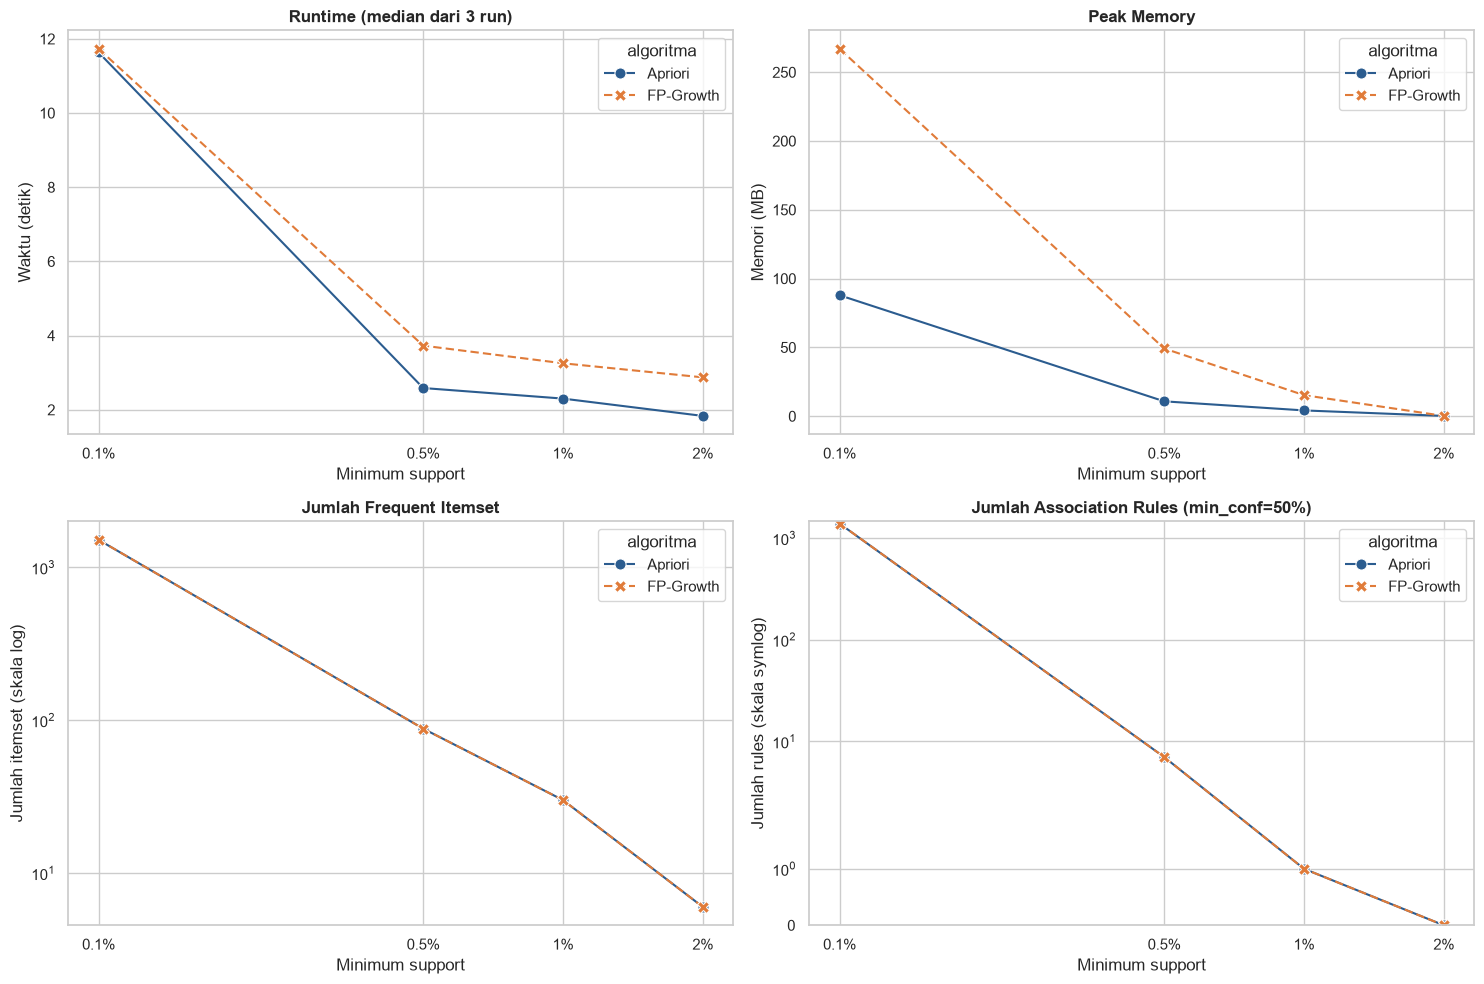

In [6]:
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
xticklabels = [f"{ms * 100:g}%" for ms in MIN_SUPPORTS]
palette = {"Apriori": "#2b5c8f", "FP-Growth": "#e07b39"}

panels = [
    ("runtime_median_s", f"Runtime (median dari {N_RUNS} run)", "Waktu (detik)", False),
    ("peak_memory_mb", "Peak Memory", "Memori (MB)", False),
    ("jumlah_itemset", "Jumlah Frequent Itemset", "Jumlah itemset (skala log)", True),
    ("jumlah_rules", f"Jumlah Association Rules (min_conf={MIN_CONFIDENCE:.0%})", "Jumlah rules (skala symlog)", True),
]

for ax, (col, title, ylabel, logy) in zip(axes.flat, panels):
    sns.lineplot(data=benchmark, x="min_support", y=col, hue="algoritma", style="algoritma",
                 markers=True, dashes=[(1, 0), (4, 2)], palette=palette, markersize=8, ax=ax)
    ax.set_xscale("log")
    ax.set_xticks(MIN_SUPPORTS)
    ax.set_xticklabels(xticklabels)
    ax.minorticks_off()
    if logy:
        ax.set_yscale("symlog" if col == "jumlah_rules" else "log")
        if col == "jumlah_rules":
            ax.set_ylim(bottom=0)
    ax.set_title(title, fontsize=12, fontweight="bold")
    ax.set_xlabel("Minimum support")
    ax.set_ylabel(ylabel)

plt.tight_layout()
plt.savefig(f"{FIGURES_DIR}/task6_algorithm_comparison{SUFFIX}.png", dpi=300, bbox_inches="tight")
plt.show()